<center> <img style="float;" src="https://oci02.img.iteso.mx/Identidades-De-Instancia/ITESO/Logos%20ITESO/Logo-ITESO-Principal.jpg" width="455" height="162.5" /> 
    
# <font color='steelblue'> Detección de fraudes en transacciones

<font color='black'>

- Ivanna herrera Ibarra
- Ana Sofía Hinojosa Bale
- Luis Fernando Márquez Bañuelos

## <font color='navy'> Librerías

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, plot_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import validation
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.ensemble import StackingClassifier
from sklearn.base import clone

warnings.filterwarnings('ignore')


## <font color='navy'> Datos

In [2]:
data_2013 = pd.read_csv('data/fraud_2013.csv')
data_2023 = pd.read_csv('data/fraud_2023.csv')

In [3]:
X_2013 = data_2013.drop(columns=['Time','Class'])
X_2023 = data_2023.drop(columns=['id','Class'])

y_2013 = data_2013['Class']
y_2023 = data_2023['Class']

## <font color='navy'> Preprocesamiento de Datos

In [4]:
# Keep only 10% of each dataset while maintaining class proportions
X_2013, _, y_2013, _ = train_test_split(
    X_2013,
    y_2013,
    train_size=0.30,
    random_state=42,
    stratify=y_2013
)

X_2023, _, y_2023, _ = train_test_split(
    X_2023,
    y_2023,
    train_size=0.30,
    random_state=42,
    stratify=y_2023
)

In [5]:
# Split the data into training and testing sets
X_train_2013, X_test_2013, y_train_2013, y_test_2013 = train_test_split(X_2013, y_2013, test_size=0.2, random_state=42, stratify=y_2013)
X_train_2023, X_test_2023, y_train_2023, y_test_2023 = train_test_split(X_2023, y_2023, test_size=0.2, random_state=42, stratify=y_2023)

In [6]:
# Standardize the "Amount" feature for both datasets
scaler_2013 = StandardScaler()
X_train_2013['Amount'] = scaler_2013.fit_transform(X_train_2013[['Amount']])
X_test_2013['Amount'] = scaler_2013.transform(X_test_2013[['Amount']])

scaler_2023 = StandardScaler()
X_train_2023['Amount'] = scaler_2023.fit_transform(X_train_2023[['Amount']])
X_test_2023['Amount'] = scaler_2023.transform(X_test_2023[['Amount']])

### <font color='skyblue'> SMOTE

In [7]:
# Create SMOTE object
smote = SMOTE(
    sampling_strategy='auto',
    k_neighbors=5,
    random_state=42
)

# Apply SMOTE to 2013 training data
X_train_2013_smote, y_train_2013_smote = smote.fit_resample(
    X_train_2013,
    y_train_2013
)

# SMOTE was previously applied to the original 2023 training data, so we can just copy the original training data for 2023
X_train_2023_smote = X_train_2023.copy()
y_train_2023_smote = y_train_2023.copy()

In [8]:
print("2013 before SMOTE:", Counter(y_train_2013))
print("2013 after SMOTE: ", Counter(y_train_2013_smote))

print("\n2023 before SMOTE:", Counter(y_train_2023))
print("2023 after SMOTE: ", Counter(y_train_2023_smote))

2013 before SMOTE: Counter({0: 68235, 1: 118})
2013 after SMOTE:  Counter({0: 68235, 1: 68235})

2023 before SMOTE: Counter({1: 68236, 0: 68235})
2023 after SMOTE:  Counter({1: 68236, 0: 68235})


## <font color='navy'> Prueba de Regresión Logística

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17059
           1       0.94      0.57      0.71        30

    accuracy                           1.00     17089
   macro avg       0.97      0.78      0.85     17089
weighted avg       1.00      1.00      1.00     17089



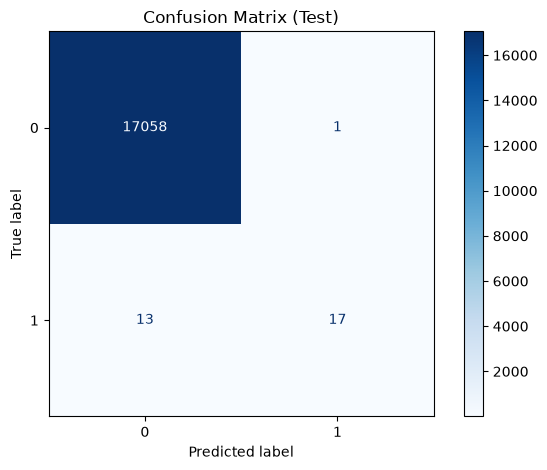

In [9]:
# Logistic Regression
model_log = LogisticRegression()
model_log.fit(X_train_2013, y_train_2013)

# Predictions
y_pred_2013 = model_log.predict(X_test_2013)

# Evaluation
print(classification_report(y_test_2013, y_pred_2013))

ConfusionMatrixDisplay.from_predictions(
    y_test_2013, y_pred_2013,
    display_labels=[0, 1],
    cmap='Blues'
)
plt.title('Confusion Matrix (Test)')

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     17059
           1       0.06      0.90      0.11        30

    accuracy                           0.97     17089
   macro avg       0.53      0.94      0.55     17089
weighted avg       1.00      0.97      0.99     17089



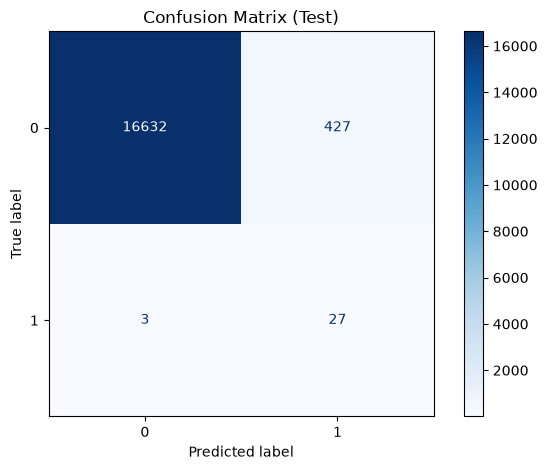

In [10]:
# Logistic Regression (SMOTE)
model_log = LogisticRegression()
model_log.fit(X_train_2013_smote, y_train_2013_smote)

# Predictions
y_pred_2013_smote = model_log.predict(X_test_2013)

# Evaluation
print(classification_report(y_test_2013, y_pred_2013_smote))

ConfusionMatrixDisplay.from_predictions(
    y_test_2013, y_pred_2013_smote,
    display_labels=[0, 1],
    cmap='Blues'
)
plt.title('Confusion Matrix (Test)')

plt.tight_layout()
plt.show()

## <font color='navy'> Modelos

### <font color='navy'> Pipeline de modelos base con SMOTE

In [11]:
log_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

In [12]:
log_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

In [13]:
meta_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

stack_model = StackingClassifier(
    estimators=[
        ('log', log_pipeline),
        ('rf', rf_pipeline)
    ],
    final_estimator=meta_model,
    stack_method='predict_proba', 
    cv=cv,                   
    passthrough=False,          
    n_jobs=-1
)

In [14]:
stack_model.fit(X_train_2013, y_train_2013)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('log', ...), ('rf', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.","XGBClassifier...ree=None, ...)"
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadd

In [15]:
y_prob_stack = stack_model.predict_proba(X_test_2013)[:, 1]
y_pred_stack = (y_prob_stack >= 0.5).astype(int)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17059
           1       0.83      0.80      0.81        30

    accuracy                           1.00     17089
   macro avg       0.91      0.90      0.91     17089
weighted avg       1.00      1.00      1.00     17089

ROC-AUC: 0.9643853684272233
PR-AUC:  0.6900780160534262


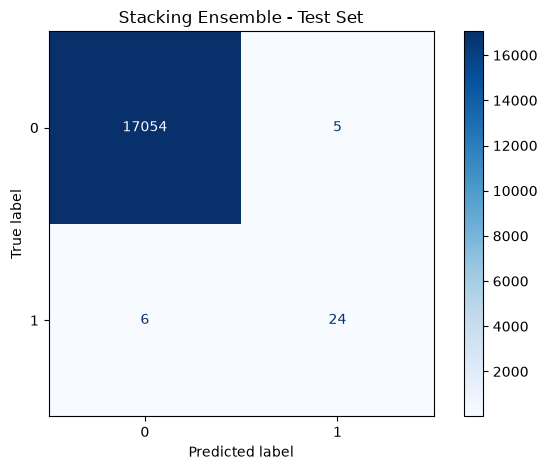

In [16]:
print(classification_report(y_test_2013, y_pred_stack))
print("ROC-AUC:", roc_auc_score(y_test_2013, y_prob_stack))
print("PR-AUC: ", average_precision_score(y_test_2013, y_prob_stack))

ConfusionMatrixDisplay.from_predictions(
    y_test_2013, y_pred_stack, display_labels=[0, 1], cmap='Blues'
)
plt.title('Stacking Ensemble - Test Set')
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    'Logistic Regression + SMOTE': clone(log_pipeline),
    'Random Forest + SMOTE': clone(rf_pipeline),
    'Stacking (LR + RF → XGB)': stack_model
}

rows = []
probs = {}
for name, m in models.items():
    if m is not stack_model:
        m.fit(X_train_2013, y_train_2013)
    p = m.predict_proba(X_test_2013)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({
        'Modelo': name,
        'Precision': precision_score(y_test_2013, pred),
        'Recall': recall_score(y_test_2013, pred),
        'F1': f1_score(y_test_2013, pred),
        'ROC-AUC': roc_auc_score(y_test_2013, p),
        'PR-AUC': average_precision_score(y_test_2013, p)
    })

results = pd.DataFrame(rows).set_index('Modelo').round(4)
display(results)

,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,
Logistic Regression + SMOTE,0.0595,0.9000,0.1116,0.9722,0.7614
Random Forest + SMOTE,0.9167,0.7333,0.8148,0.9777,0.8090
Stacking (LR + RF → XGB),0.8276,0.8000,0.8136,0.9644,0.6901


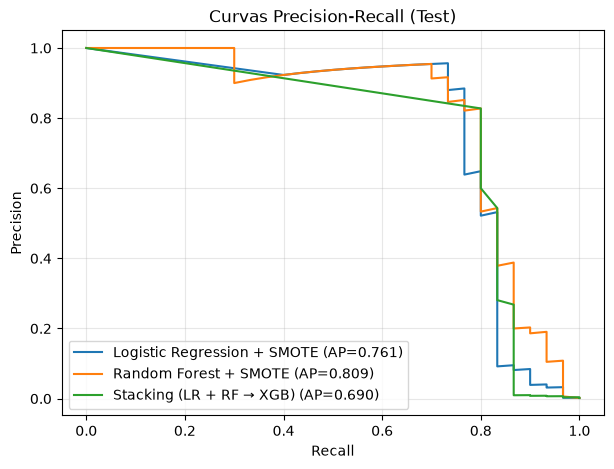

In [18]:
plt.figure(figsize=(7, 5))
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test_2013, p)
    ap = average_precision_score(y_test_2013, p)
    plt.plot(rec, prec, label=f'{name} (AP={ap:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curvas Precision-Recall (Test)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
oof_prob = cross_val_predict(
    clone(stack_model),
    X_train_2013,
    y_train_2013,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    method='predict_proba'
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train_2013, oof_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best_thr = thr[np.argmax(f1[:-1])]
print("Umbral óptimo (OOF):", round(best_thr, 4))

y_pred_thr = (y_prob_stack >= best_thr).astype(int)
print(classification_report(y_test_2013, y_pred_thr))

Umbral óptimo (OOF): 0.6582
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17059
           1       0.83      0.80      0.81        30

    accuracy                           1.00     17089
   macro avg       0.91      0.90      0.91     17089
weighted avg       1.00      1.00      1.00     17089

